# 25 EPI from our own measurements, the precursor's spectrum, and what the numbers mean

Notebooks 23 and 24 measured Zhu et al.'s bursts again, with error bars. Here those numbers go back into their index, and then into
physics.

1. EPI from our numbers, with its uncertainty
2. What EPI's uncertainty is made of
3. Our EPI against their types
4. Does the precursor's E_peak add anything?
5. The delay from precursor to main emission as an inspiral time
6. How large the precursor's emitting region can be
7. Energetics, the Amati plane and the shattering-flare budget
8. Their numbers against ours, one by one
9. The table
10. What this says

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

from grbtool.physics import TYPE_I, TYPE_II, amati_offsets, budget, energetics, z_for_budget
from zhu import RESULTS
from zhu import physics as P
from zhu.catalogue import EPI_LINE, epi, read_table_2026
from zhu.classify import probability_above
from zhu.features import collect, epi_summary

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
FIGURES = Path("figures")
COLOURS = {"I-S": "#2a78d6", "I-L": "#eb6834", "II": "0.6"}

table = read_table_2026()
sample = pd.read_csv("shared/zhu_sample.csv", comment="#", index_col=0)
ours = collect("zhu2026")
ours["Type"] = table.loc[ours.index, "Type"]
ours["merger"] = ours.Type.str.startswith("I-")
ours["their_EPI"] = table.loc[ours.index, "EPI"]
ours["z"] = sample.loc[ours.index, "z"]
summary = epi_summary(ours, way="zhu").join(epi_summary(ours, way="ours"))
ours = ours.join(summary)
# EPI with our rule's E_p,ME only where our rule measures it (GRB 170310A's and 190829A's it doesn't)
ours.loc[ours.measured_ME != True, [c for c in summary.columns if c.endswith('_ours')]] = np.nan
has = ours.EPI_zhu.notna()
print(int(has.sum()), "bursts with EPI from our numbers (their way of fitting);", ours[has].Type.value_counts().to_dict())

95 bursts with EPI from our numbers (their way of fitting); {'II': 58, 'I-S': 30, 'I-L': 7}


## 1. EPI from our numbers, with its uncertainty

EPI = log10[E_p,ME^2 / (T100,PE T100,QE1^(1/2) T_MVT,PE)], with E_p,ME from their models and BIC (notebook 24) and the three times from
notebook 23. The uncertainty comes from drawing EPI 4000 times (`features.epi_samples`). The three times move together, the way they do in
that burst's simulated light curves (only the ones in which the precursor was found), and log E_p,ME is drawn from a normal with a
different width on each side, set by its two profile-likelihood errors. A burst whose E_p,ME has no error gets no draws. P_above is the
share of draws above 6.2.

In [2]:
d = ours[has]
diff = d.EPI_zhu - d.their_EPI
print("ours minus theirs: median", round(diff.median(), 2), "scatter", round(diff.std(), 2), "; within 0.2:", round(np.mean(np.abs(diff) < 0.2), 2), "; within 0.5:", round(np.mean(np.abs(diff) < 0.5), 2))
width = (d.EPI_p84_zhu - d.EPI_p16_zhu) / 2
print("our 68% half-width: median", round(width.median(), 2), "; 16-84% of bursts", round(width.quantile(0.16), 2), "-", round(width.quantile(0.84), 2))
side_theirs = d.their_EPI > EPI_LINE
side_ours = d.EPI_zhu > EPI_LINE
print("same side of 6.2 as their EPI:", int((side_theirs == side_ours).sum()), "of", len(d))
unsure = d[(d.P_above_zhu > 0.05) & (d.P_above_zhu < 0.95)]
print("bursts whose side is not settled (P_above between 0.05 and 0.95):", len(unsure))
cols = ["Type", "their_EPI", "EPI_zhu", "EPI_p16_zhu", "EPI_p84_zhu", "P_above_zhu", "EPI_ours"]
d[(side_theirs != side_ours) | d.index.isin(unsure.index)][cols].sort_values("their_EPI").round(2)

ours minus theirs: median -0.02 scatter 0.81 ; within 0.2: 0.35 ; within 0.5: 0.57
our 68% half-width: median 0.4 ; 16-84% of bursts 0.29 - 0.55
same side of 6.2 as their EPI: 90 of 95
bursts whose side is not settled (P_above between 0.05 and 0.95): 19


,Type,their_EPI,EPI_zhu,EPI_p16_zhu,EPI_p84_zhu,P_above_zhu,EPI_ours
name,,,,,,,
210606B,II,3.11,5.01,4.86,5.82,0.07,5.15
220305A,II,3.14,4.34,3.72,5.23,0.07,4.38
130206B,II,3.79,6.41,5.99,7.00,0.68,6.37
170310A,II,3.96,7.02,4.32,7.38,0.46,NaN
170306B,II,5.18,5.61,5.33,6.14,0.14,5.72
141121B,II,5.26,4.67,4.37,5.59,0.06,4.62
160825A,II,5.29,6.39,6.05,6.91,0.72,6.40
200714E,II,5.37,6.06,5.68,6.66,0.40,6.13
190114C,II,5.50,5.07,4.87,5.64,0.08,5.04


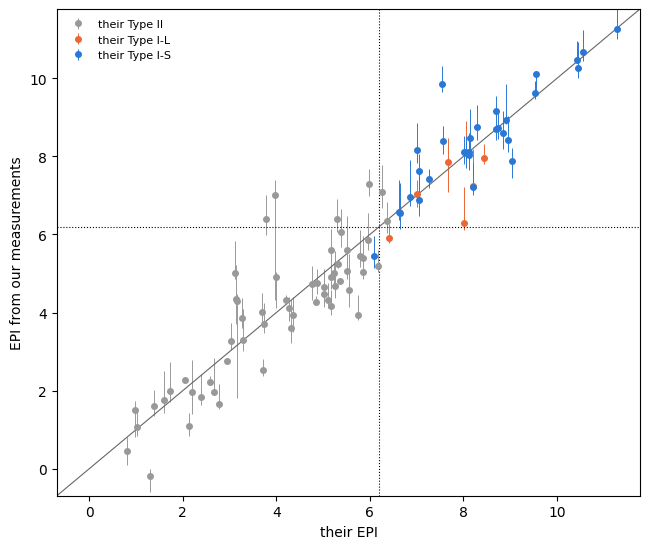

In [3]:
fig, ax = plt.subplots(figsize=(6.6, 5.6))
for kind in ("II", "I-L", "I-S"):
    s = d[d.Type == kind]
    ax.errorbar(s.their_EPI, s.EPI_zhu, yerr=[(s.EPI_zhu - s.EPI_p16_zhu).clip(lower=0), (s.EPI_p84_zhu - s.EPI_zhu).clip(lower=0)], fmt="o", ms=4,
                color=COLOURS[kind], elinewidth=0.7, label=f"their Type {kind}")
lim = [min(d.their_EPI.min(), d.EPI_zhu.min()) - 0.5, max(d.their_EPI.max(), d.EPI_zhu.max()) + 0.5]
ax.plot(lim, lim, color="0.4", lw=0.8)
ax.axhline(EPI_LINE, color="k", lw=0.8, ls=":"); ax.axvline(EPI_LINE, color="k", lw=0.8, ls=":")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("their EPI"); ax.set_ylabel("EPI from our measurements")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "25_epi_ours_against_theirs.png", dpi=140)
plt.show()

Burst by burst, our EPI agrees with theirs only loosely. The median offset is -0.02, but the scatter is 0.81, with 35% within 0.2 and 57%
within 0.5. Our own uncertainty is about +-0.4 (the median 68% half-width, 0.29-0.55 over the bursts), so most of that scatter is what
EPI's inputs allow. Even so, 90 of 95 bursts fall on the same side of 6.2 as in their table. 19 have a chance between 5% and 95% of lying
above the line, so the data don't settle their side. The table lists them, and they sit near the line in both measurements.

## 2. What EPI's uncertainty is made of

The statistical part, input by input (E_p,ME counts twice and T100,QE1 half), and the systematic shifts from three choices: the reading of
the MVT (notebook 23, section 4), the time bin (half and twice their Tres), and the way E_p,ME is fitted (notebook 24).

In [4]:
half = lambda lo, hi, v: 0.5 * (np.log10(hi) - np.log10(lo))
parts = pd.DataFrame(index=d.index)
parts["E_p,ME (x2)"] = 2 * 0.5 * (np.log10(d.Ep_ME_zhu + d.Ep_ME_zhu_hi) - np.log10((d.Ep_ME_zhu - d.Ep_ME_zhu_lo).clip(lower=1)))
parts["T100,PE"] = half(d.T100_PE_p16, d.T100_PE_p84, d.T100_PE)
parts["T100,QE1 (x1/2)"] = 0.5 * half(d.T100_QE1_p16, d.T100_QE1_p84, d.T100_QE1)
parts["T_MVT,PE"] = half(d.TMVT_PE_p16, d.TMVT_PE_p84, d.TMVT_PE)
print("statistical part, median over bursts (dex of EPI):")
print(parts.median().round(3).to_string())
systematic = pd.DataFrame(index=d.index)
for reading in ("shortest", "rise", "half_width"):
    systematic[f"MVT read as '{reading}'"] = -np.log10(d[f"TMVT_PE_{reading}"].astype(float) / d.TMVT_PE)
for tag, label in (("half", "half their Tres"), ("double", "twice their Tres")):
    if f"T100_PE_{tag}" in d:
        systematic[label] = epi(d.Ep_ME_zhu, d[f"T100_PE_{tag}"], d[f"T100_QE1_{tag}"], d[f"TMVT_PE_{tag}"]) - d.EPI_zhu
systematic["E_p,ME by our rule"] = d.EPI_ours - d.EPI_zhu
print("systematic shifts of EPI (dex): median and the spread of the middle 68% of bursts")
print(pd.DataFrame({"median": systematic.median(), "p16": systematic.quantile(0.16), "p84": systematic.quantile(0.84), "bursts": systematic.notna().sum()}).round(2).to_string())

statistical part, median over bursts (dex of EPI):
E_p,ME (x2)        0.102
T100,PE            0.026
T100,QE1 (x1/2)    0.006
T_MVT,PE           0.334
systematic shifts of EPI (dex): median and the spread of the middle 68% of bursts
                          median   p16   p84  bursts
MVT read as 'shortest'      0.08 -0.37  0.69      95
MVT read as 'rise'         -0.03 -0.37  0.19      95
MVT read as 'half_width'    0.00 -0.45  0.29      95
half their Tres             0.01 -0.29  0.41      88
twice their Tres           -0.00 -0.28  0.24      84
E_p,ME by our rule          0.01 -0.04  0.10      93


Almost all of EPI's statistical uncertainty is T_MVT,PE's: a median of 0.33 dex, against 0.10 from E_p,ME (which enters twice), 0.03 from
T100,PE and 0.01 from the gap. That's the counting noise in the position of the brightest bin (notebook 23). The choices behave the same
way. Reading the MVT another way moves EPI by 0.4-0.7 for a third of the bursts, and halving or doubling the bin moves it by 0.2-0.4,
while fitting E_p,ME by our rule instead of their way moves it by 0.1 or less for most bursts. So EPI is set mostly by the precursor's
timing, and the precursor's MVT is its weakest part.

## 3. Our EPI against their types

In [5]:
for way in ("zhu", "ours"):
    s = ours[ours[f"EPI_{way}"].notna()]
    above = s[f"EPI_{way}"] > EPI_LINE
    print(f"EPI with E_p,ME {'their way' if way == 'zhu' else 'by our rule'}: {len(s)} bursts, adjusted Rand index with their types {adjusted_rand_score(s.merger, above):.2f},",
          f"Type I above the line {above[s.merger].mean():.2f}, Type II below {(~above[~s.merger]).mean():.2f}, area under ROC {roc_auc_score(s.merger, s[f'EPI_{way}']):.3f}")
s = ours[has]
print("their own EPI on the same bursts: adjusted Rand index", round(adjusted_rand_score(s.merger, s.their_EPI > EPI_LINE), 2))
groups = {"bursts of known origin (a kilonova, or a supernova)": ("211211A", "230307A", "090618A", "111228A", "180728A", "190114C", "190829A", "211023A"),
          "short bursts with a host galaxy's redshift (candidates, not confirmed)": ("090510A", "111117A", "161001A")}
for title, names in groups.items():
    print(title + ":")
    for name in names:
        if name in ours.index and pd.notna(ours.EPI_zhu.get(name)):
            r = ours.loc[name]
            print(f"   {name} {r.Type:4s} theirs {r.their_EPI:5.2f}  ours {r.EPI_zhu:5.2f} ({r.EPI_p16_zhu:.2f}-{r.EPI_p84_zhu:.2f}), P above 6.2 = {r.P_above_zhu:.2f}")
        else:
            print(f"   {name} no EPI from our numbers (no precursor under the zhu2026 rule, or not measured)")

EPI with E_p,ME their way: 95 bursts, adjusted Rand index with their types 0.69, Type I above the line 0.95, Type II below 0.90, area under ROC 0.982
EPI with E_p,ME by our rule: 94 bursts, adjusted Rand index with their types 0.72, Type I above the line 0.95, Type II below 0.91, area under ROC 0.984
their own EPI on the same bursts: adjusted Rand index 0.88
bursts of known origin (a kilonova, or a supernova):
   211211A I-L  theirs  8.45  ours  7.97 (7.79-8.31), P above 6.2 = 1.00
   230307A no EPI from our numbers (no precursor under the zhu2026 rule, or not measured)
   090618A II   theirs  2.12  ours  1.09 (0.85-1.44), P above 6.2 = 0.00
   111228A no EPI from our numbers (no precursor under the zhu2026 rule, or not measured)
   180728A II   theirs  2.67  ours  1.97 (1.90-2.83), P above 6.2 = 0.00
   190114C II   theirs  5.50  ours  5.07 (4.87-5.64), P above 6.2 = 0.08
   190829A II   theirs  1.31  ours -0.19 (-0.60--0.02), P above 6.2 = 0.00
   211023A II   theirs  0.81  ours  0.4

With our numbers EPI still separates their types well (area under the ROC curve 0.982), but less cleanly than their own values do. The
adjusted Rand index is 0.69 against 0.88 on the same bursts, with 95% of their Type I above the line and 90% of their Type II below. That's
expected, since their types were found from their own numbers and ours carry the scatter above. The confirmed bursts fall where their
origin says: GRB 211211A at 7.97, above the line, and the supernova collapsars below it (GRB 190829A at -0.19, 211023A at 0.45, 090618 at
1.09, 180728A at 1.97, 190114C at 5.07). GRB 190829A's is 1.5 below theirs, mostly because its main emission peaks at the bottom of GBM's
band (7.8 keV their way, against 39 keV in their table, notebook 24), and on either value it's far below the line. GRB 230307A has no EPI
of ours because the rule finds no precursor (notebook 23). The short bursts with a host redshift are candidates: GRB 090510 at 11.25, and
161001A at 5.45, below the line although their table puts it at 6.10.

## 4. Does the precursor's E_peak add anything?

This is the question the project started with. Their types come from timing numbers and E_p,ME, and the precursor's own spectrum was
never used, so it's an independent check. There are two tests, on the bursts whose precursor and main-emission E_peaks are both measured
(by our rule, since the ratio needs both): how well it separates their types on its own, and whether adding it to EPI improves a logistic
model of their types (5-fold cross-validation repeated 20 times, where a lower log loss is better).

In [6]:
m = ours[(ours.measured_PE == True) & (ours.measured_ME == True) & ours.EPI_zhu.notna() & ours.Ep_PE_ours.notna()].copy()
m["log_Ep_PE"] = np.log10(m.Ep_PE_ours)
m["log_ratio"] = np.log10(m.Ep_PE_ours / m.Ep_ME_ours)
print(len(m), "bursts;", m.Type.value_counts().to_dict())
for column in ("log_Ep_PE", "log_ratio", "EPI_zhu"):
    auc = roc_auc_score(m.merger, m[column])
    print(f"   {column}: area under ROC {max(auc, 1 - auc):.2f} ({'higher' if auc >= 0.5 else 'lower'} in Type I)")
folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=7)
def loss(columns):
    model = LogisticRegression(C=1.0)
    return -cross_val_score(model, m[columns].values, m.merger.values, cv=folds, scoring="neg_log_loss")
results = {"EPI": loss(["EPI_zhu"]), "EPI + E_p,PE": loss(["EPI_zhu", "log_Ep_PE"]), "EPI + E_p,PE/E_p,ME": loss(["EPI_zhu", "log_ratio"]), "E_p,PE alone": loss(["log_Ep_PE"])}
base = results["EPI"]
for name, values in results.items():
    print(f"   {name:22s} log loss {values.mean():.3f} +/- {values.std() / np.sqrt(len(values)):.3f};  better than EPI alone in {np.mean(values < base):.0%} of the folds")

69 bursts; {'II': 40, 'I-S': 23, 'I-L': 6}
   log_Ep_PE: area under ROC 0.64 (higher in Type I)
   log_ratio: area under ROC 0.70 (lower in Type I)
   EPI_zhu: area under ROC 0.99 (higher in Type I)


   EPI                    log loss 0.179 +/- 0.011;  better than EPI alone in 0% of the folds
   EPI + E_p,PE           log loss 0.180 +/- 0.011;  better than EPI alone in 62% of the folds
   EPI + E_p,PE/E_p,ME    log loss 0.180 +/- 0.011;  better than EPI alone in 59% of the folds
   E_p,PE alone           log loss 0.664 +/- 0.004;  better than EPI alone in 0% of the folds


On the 69 bursts whose precursor and main-emission E_peaks our rule both measures, the precursor's E_peak alone separates their types only
weakly (area 0.64, harder in Type I), and so does its ratio to the main emission (0.70, lower in Type I), against 0.99 for EPI. Adding
either one to EPI leaves the out-of-sample log loss where it was (0.179 against 0.180, better in 59-62% of the folds, which isn't far from
the half that a column of noise would give). Notebook 26 tests this properly, with permutations, limits and the confirmed bursts.

## 5. The delay from precursor to main emission as an inspiral time

`zhu/physics.py`: two neutron stars of 1.4 solar masses reach a gravitational-wave frequency f a time
tau = (5/256)(G M_c/c^3)^(-5/3)(pi f)^(-8/3) before merging, which is 2.2 s at 100 Hz. If a Type I precursor is a resonant shattering flare
(Tsang et al. 2012), it starts when f reaches the crust-core interface mode, and the main emission can't start before the merger. So the
delay from the start of the precursor to the start of the main emission, in the rest frame, is at least tau, and that gives the lowest
mode frequency the burst allows. Without a redshift I use the observed delay, which gives the lowest limit any redshift would allow.

In [7]:
limits = P.delay_limits(ours[ours.pe_start.notna()], ours.z)
limits["Type"] = ours.Type
typeI = limits[limits.Type.str.startswith("I-")].sort_values("f_min_bns")
print("Type I: delay from precursor start to main start (s) and the lowest interface-mode frequency it allows (Hz)")
print(typeI[["Type", "z", "delay_obs", "delay_rest", "f_min_bns", "f_min_nsbh"]].round(3).to_string())
print("below 100 Hz (two neutron stars):", int((typeI.f_min_bns < 100).sum()), "of", len(typeI), "; median lower limit", round(typeI.f_min_bns.median()), "Hz")
print("Type II delays for comparison (s): median", round(limits[limits.Type == "II"].delay_obs.median(), 2), "range", round(limits[limits.Type == "II"].delay_obs.min(), 2), "-", round(limits[limits.Type == "II"].delay_obs.max(), 1))

Type I: delay from precursor start to main start (s) and the lowest interface-mode frequency it allows (Hz)
        Type      z  delay_obs  delay_rest  f_min_bns  f_min_nsbh
name                                                             
131209B  I-S    NaN     15.616      15.616     47.621      32.762
130310A  I-S    NaN      4.608       4.608     75.262      51.777
240513A  I-S    NaN      3.904       3.904     80.089      55.098
180605A  I-S    NaN      2.928       2.928     89.213      61.375
200311A  I-L    NaN      2.368       2.368     96.605      66.460
131215B  I-L    NaN      2.208       2.208     99.173      68.227
211019A  I-L    NaN      2.024       2.024    102.462      70.490
170228A  I-L    NaN      1.920       1.920    104.509      71.898
200914A  I-L    NaN      1.776       1.776    107.609      74.031
170802A  I-S    NaN      1.744       1.744    108.346      74.537
240411A  I-S    NaN      1.656       1.656    110.470      75.999
161001A  I-S    NaN      1.648    

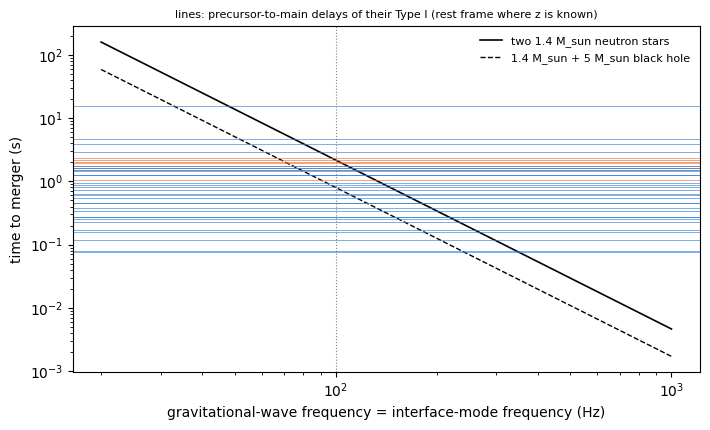

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
f = np.logspace(1.3, 3.0, 200)
ax.plot(f, P.inspiral_time(f, P.BNS), color="k", lw=1.2, label="two 1.4 M_sun neutron stars")
ax.plot(f, P.inspiral_time(f, P.NSBH), color="k", lw=1.0, ls="--", label="1.4 M_sun + 5 M_sun black hole")
for _, r in typeI.iterrows():
    ax.axhline(r.delay_rest, color=COLOURS[r.Type], lw=0.6, alpha=0.7)
ax.axvline(100, color="0.5", lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("gravitational-wave frequency = interface-mode frequency (Hz)")
ax.set_ylabel("time to merger (s)")
ax.set_title("lines: precursor-to-main delays of their Type I (rest frame where z is known)", fontsize=8)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "25_inspiral_time.png", dpi=140)
plt.show()

What's measured: the delay from the precursor's start to the main emission's in their Type I bursts runs from 0.08 s to 15.6 s, with a
median of 0.9 s, and two thirds of them are between 0.4 and 3 s. My interpretation: if a precursor is a resonant shattering flare, it
happens when the gravitational-wave frequency (twice the orbital frequency) reaches the frequency of the crust-core interface mode. If the
main emission starts soon after the merger, the delay is the time left from that frequency to the merger, so it sets the lowest mode
frequency the delay allows. For two 1.4 solar-mass neutron stars, a delay of 1-2 s means about 105-135 Hz, close to the 100 Hz or so
expected for interface modes (Tsang et al. 2012). The longest delay (GRB 131209B, 15.6 s) would need a mode near 50 Hz, which is low for
most models. This is a consistency test of one model, not a measurement of the mode.

## 6. How large the precursor's emitting region can be

A region that changes on a time dt is at most about c dt across if it isn't moving towards us (`physics.light_size_km`). For comparison, a
neutron star's radius is about 12 km. Two 1.4 solar-mass stars whose gravitational waves are at 100 Hz orbit 50 times a second, about 160 km
apart (Kepler's law), and the light cylinder of that orbit, c / (2 pi f_orb), is about 950 km. A Wolf-Rayet star, the kind thought to make
collapsars, has a radius of order 10^6 km.

In [9]:
size = pd.DataFrame(index=ours.index)
size["Type"] = ours.Type
size["TMVT_PE"] = ours.TMVT_PE
size["size_km"] = P.light_size_km(ours.TMVT_PE, ours.z.fillna(0.0))
print("c T_MVT,PE (km), with the redshift where known:")
print(size.groupby("Type").size_km.describe()[["count", "min", "25%", "50%", "75%", "max"]].round(0).to_string())
print("orbital light cylinder at f_GW = 100 Hz:", round(3e5 / (2 * np.pi * 50)), "km")

c T_MVT,PE (km), with the redshift where known:
      count     min      25%       50%       75%        max
Type                                                       
I-L     7.0  3901.0  12591.0   21585.0   63556.0   129510.0
I-S    31.0   630.0   3897.0   10793.0   41371.0   265017.0
II     58.0  2398.0  63856.0  173882.0  720701.0  8759979.0
orbital light cylinder at f_GW = 100 Hz: 955 km


c T_MVT,PE gives the largest region the precursor can come from if it isn't moving towards us: a median of about 11,000 km for their Type
I-S precursors and 22,000 km for I-L, against 174,000 km for Type II. Those are all far larger than a neutron star (12 km) or the binary's
light cylinder at 100 Hz (955 km), so they don't rule out an origin at the merger. They only say that Type II precursors vary more slowly.
With beaming the limit is larger still (2 Gamma^2 c T_MVT), and T_MVT,PE itself carries the 0.4 dex counting noise of notebook 23.

## 7. Energetics, the Amati plane and the shattering-flare budget

For the bursts with a redshift (`shared/redshifts_greiner.csv`, with the project's own values first), the precursor and the main emission
from our rule (`grbtool.physics.energetics`, k-corrected to 1-10^4 keV in the rest frame). The Amati tracks are Minaev and Pozanenko's
(2020). The budget follows notebook 19: the tidal energy rate a precursor needs is L_iso / 0.2 against the fiducial 1e50 erg/s, and the
surface field it needs is B_min = 1.2e15 G (L_iso / 3.6e50 erg/s)^(1/2), both in 10-1000 keV with no k-correction, as Dichiara et al.
define them.

In [10]:
rows = []
for name in ours.index[ours.z.notna()]:
    path = RESULTS / name / "spectra_zhu2026.csv"
    if not path.exists():
        continue
    fits = pd.read_csv(path, index_col=0)
    for label in ("PE", "ME"):
        if label not in fits.index or not fits.loc[label].get("measured", False) or pd.isna(fits.loc[label].get("flux")):
            continue
        row = fits.loc[label]
        e = energetics(row, ours.z[name])
        rows.append(dict(GRB=name, Type=ours.Type[name], z=ours.z[name], episode=label, Epeak_obs=row.Epeak, **e, **amati_offsets(e["E_iso"], e["Epeak_rest"]),
                         **(budget(e["L_iso_no_k"]) if label == "PE" else {})))
energy = pd.DataFrame(rows)
cols = ["GRB", "Type", "z", "episode", "Epeak_rest", "E_iso", "L_iso", "dex_from_type_I", "dex_from_type_II", "rate_over_fiducial", "B_min_G"]
if energy.empty:
    print("no burst with a redshift has a measured spectrum yet")
else:
    print(energy[[c for c in cols if c in energy]].to_string(index=False, float_format=lambda x: f"{x:.3g}"))

    GRB Type      z episode  Epeak_rest    E_iso    L_iso  dex_from_type_I  dex_from_type_II  rate_over_fiducial  B_min_G
090510A  I-S  0.903      PE         676 3.17e+50 1.51e+52            0.205              1.28                 726 7.62e+15
090510A  I-S  0.903      ME    9.07e+03  4.1e+52 8.72e+52            0.466               1.5                 NaN      NaN
090618A   II   0.54      PE         402 2.93e+52  1.3e+51           -0.827             0.214                  63 2.25e+15
090618A   II   0.54      ME         371 2.06e+53 6.39e+51            -1.21            -0.185                 NaN      NaN
111117A  I-S   2.21      ME    2.15e+03 1.14e+52 8.34e+52           0.0681              1.12                 NaN      NaN
160509A   II   1.17      PE         873 1.64e+52 6.84e+51           -0.387             0.659                 302 4.91e+15
160509A   II   1.17      ME    1.31e+03 8.51e+53 5.04e+52           -0.916            0.0958                 NaN      NaN
180728A   II  0.117     

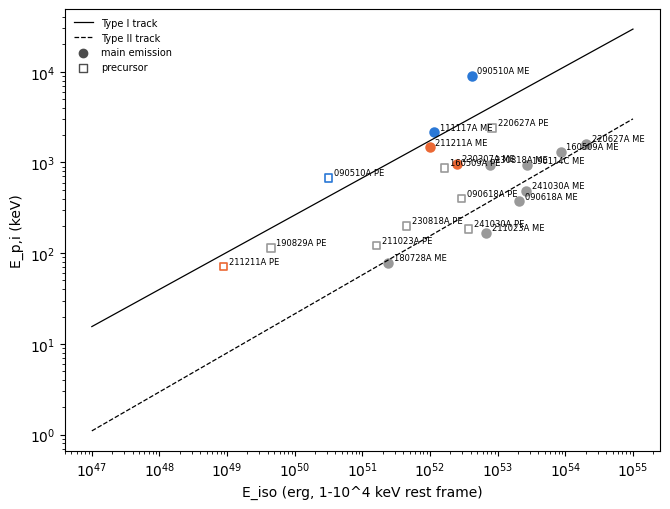

Type I precursors without a redshift: the redshift at which each would need the fiducial tidal rate, and 18 times it (GRB 230307A's)
        Type flux_10_1000keV_erg_cm2_s  z_at_fiducial  z_at_18_times
GRB                                                                 
081216A  I-S                  5.53e-07          0.114          0.414
090831A  I-S                  9.16e-07          0.090          0.334
130310A  I-S                  5.06e-07          0.119          0.430
130804A  I-S                  4.43e-06          0.042          0.166
141102A  I-S                  2.80e-06          0.053          0.204
150228A  I-S                  2.65e-06          0.054          0.209
150604B  I-S                  2.26e-06          0.059          0.225
150702A  I-S                  1.94e-06          0.063          0.241
151222A  I-S                  1.72e-06          0.067          0.254
160726A  I-S                  2.22e-06          0.059          0.227
160804B  I-S                  3.18e-06 

In [11]:
fig, ax = plt.subplots(figsize=(6.8, 5.2))
e_iso = np.logspace(47, 55, 50)
for (a, b), label, ls in ((TYPE_I, "Type I track", "-"), (TYPE_II, "Type II track", "--")):
    ax.plot(e_iso, 100 * 10 ** (a * np.log10(e_iso / 1e51) + b), color="k", lw=0.9, ls=ls, label=label)
for _, r in energy.iterrows():
    ax.scatter(r.E_iso, r.Epeak_rest, marker="o" if r.episode == "ME" else "s", s=40 if r.episode == "ME" else 30,
               facecolor=COLOURS[r.Type] if r.episode == "ME" else "none", edgecolor=COLOURS[r.Type], lw=1.2)
    ax.annotate(f"{r.GRB} {r.episode}", (r.E_iso, r.Epeak_rest), xytext=(4, 2), textcoords="offset points", fontsize=6)
ax.scatter([], [], marker="o", color="0.3", label="main emission"); ax.scatter([], [], marker="s", facecolor="none", edgecolor="0.3", label="precursor")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("E_iso (erg, 1-10^4 keV rest frame)"); ax.set_ylabel("E_p,i (keV)")
ax.legend(frameon=False, fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "25_amati.png", dpi=140)
plt.show()

budget_rows = []
for name in ours.index[ours.merger & ours.z.isna()]:
    path = RESULTS / name / "spectra_zhu2026.csv"
    if path.exists():
        fits = pd.read_csv(path, index_col=0)
        if "PE" in fits.index and fits.loc["PE"].get("measured", False) and pd.notna(fits.loc["PE"].get("flux")):
            flux = fits.loc["PE"].flux
            budget_rows.append(dict(GRB=name, Type=ours.Type[name], flux=flux, z_at_fiducial=z_for_budget(flux, 1.0), z_at_18_times=z_for_budget(flux, 18.0)))
no_z = pd.DataFrame(budget_rows).set_index("GRB") if budget_rows else pd.DataFrame()
print("Type I precursors without a redshift: the redshift at which each would need the fiducial tidal rate, and 18 times it (GRB 230307A's)")
if len(no_z):
    no_z["flux"] = no_z.flux.map(lambda f: f"{f:.2e}")
    print(no_z.rename(columns={"flux": "flux_10_1000keV_erg_cm2_s"}).round(3).to_string())
else:
    print("none")

For the bursts with a redshift, the main emissions lie near the Amati relation of their type, but the precursors don't sort that way. GRB
211211A's and 090510's lie near the Type I track, and so do the Type II precursors of GRB 160509A, 190829A and 220627A. So the precursor's
place on the Amati plane isn't a clean indicator either. GRB 211211A's precursor (E_p,i = 71 keV, E_iso = 8.9e48 erg) needs about the
fiducial tidal energy rate (0.97 times) for a shattering flare. My interpretation: the Type I precursors without a redshift would need the
fiducial rate at z = 0.04-0.14, and 18 times it (GRB 230307A's case) at z = 0.17-0.51. So a shattering flare is plausible for them only if
they're nearby, which a redshift would test.

## 8. Their numbers against ours, one by one

For every burst and every number in their table: their value, ours, the difference, our 68% interval, whether they agree (their value
inside our interval, or within 0.05 dex), our number's status (zhu/quality.py) and, when they don't agree, the known reason
(`features.paper_vs_ours`). It's saved as `shared/zhu_paper_vs_ours.csv`.

In [12]:
from zhu.features import paper_vs_ours
comparison = paper_vs_ours(ours, table)
comparison.to_csv(Path("shared") / "zhu_paper_vs_ours.csv", index=False, float_format="%.5g")
summary = comparison.groupby("number").agg(bursts=("ours", lambda v: int(np.isfinite(v).sum())), agree=("agrees", "mean"))
print(summary.round(2).to_string())
reasons = comparison[~comparison.agrees & comparison.reason.ne("")].groupby(["number", comparison.reason.str.split(" [(]").str[0]]).size()
print(reasons.to_string())

             bursts  agree
number                    
EPI              95   0.48
Ep_ME           109   0.55
T100_ME         110   0.58
T100_PE          96   0.55
T100_QE1         96   0.58
T100_WE         110   0.66
TMVT_ME         110   0.73
TMVT_PE          96   0.67
tau32_ME_ms      88   0.36
tau32_WE_ms      92   0.36
number       reason                               
EPI          edge                                      1
             missing                                  15
             other                                     9
             other gap                                 4
             same gap, other start                    28
Ep_ME        model or window                          48
             unusable                                  1
T100_ME      extended-emission split or faint tail    46
T100_PE      edge                                      1
             missing                                  14
             other                                    1

Every number of their table against ours, burst by burst. EPI agrees (their value inside our interval or within 0.05 dex) for 48% of the
bursts, E_p,ME for 55%, the durations for 55-66%, T_MVT for 67-73% and the lags for 36%. Each disagreement carries a label. For EPI it's
mostly "same gap, other start" (28) or no precursor (15). For the precursor's and the gap's durations it's no precursor, the same gap with
another start, or another dip. For the main emission's duration it's the split of the extended emission or a faint tail, for E_p,ME the
model or the window, for T_MVT the reading, and for the lags their resolution or window. Where none of these fits, the label is "other":
9 of the EPI disagreements, and 14 and 17 of the precursor's and the gap's.

## 9. The table

Everything measured for each burst, in one file for anyone who wants to use it: `shared/zhu_remeasured.csv` (the column names and units are
in its header).

In [13]:
from zhu.features import write_table
everyone = collect("zhu2026", names=sample.index).join(ours.filter(regex="^(EPI|P_above)"))   # every burst of the sample, measured or not
written = write_table(everyone, Path("shared") / "zhu_remeasured.csv")
print(written.shape[0], "bursts,", written.shape[1], "columns;", written.status.value_counts().to_dict())
written[["T100_PE_s", "T100_QE1_s", "TMVT_PE_s", "Ep_ME_their_way_keV", "Ep_PE_our_rule_keV", "EPI", "EPI_p16", "EPI_p84", "P_EPI_above_6.2"]].head(8).round(3)

111 bursts, 72 columns; {'complete': 110, 'not_measurable': 1}


,T100_PE_s,T100_QE1_s,TMVT_PE_s,Ep_ME_their_way_keV,Ep_PE_our_rule_keV,EPI,EPI_p16,EPI_p84,P_EPI_above_6.2
name,,,,,,,,,
090131A,0.592,1.780,0.102,64.968,29122.283,4.719,4.333,5.195,0.024
090618A,34.720,15.328,20.228,184.259,261.118,1.092,0.850,1.438,0.000
090831A,0.032,0.240,0.014,330.299,60.817,8.696,8.409,9.093,1.000
091010A,2.012,0.504,0.750,142.978,201.286,4.281,4.224,4.420,0.000
110825A,3.200,3.880,0.074,227.529,26.459,5.045,4.865,5.557,0.074
111228A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140206B,1.680,4.592,0.564,208.384,272.526,4.330,4.242,4.456,0.000
140810A,20.064,5.144,0.212,290.460,431.687,3.942,3.506,4.405,0.000


## 10. What this says

From our numbers, EPI separates their types almost as well as their own values do (area 0.98) and puts the confirmed bursts where their
origin says. But burst by burst it carries about +-0.4 of uncertainty, almost all of it from T_MVT,PE, and 19 bursts have no settled side.
The precursor's own E_peak adds nothing to it here, and notebook 26 tests that properly. The physics is a set of consistency tests, not
measurements: delays of about a second before the main emission fit a shattering flare from interface modes near 100 Hz, c T_MVT,PE is far
too large to constrain the source, and GRB 211211A's precursor needs about the fiducial tidal energy release.